In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ipynb.fs.full.model import evaluate_model,plot_loss_and_mae

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import tensorflow as tf

I0000 00:00:1795516351.262506 3760256 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795516351.296785 3760256 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795516352.002803 3760256 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
def build_nn_model(input_dim, output_dim, architecture='standard'):
    """Build a neural network model with specified architecture"""
    
    if architecture == 'standard':
        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(input_dim,)),
            tf.keras.layers.Dense(32, activation='relu'),
            tf.keras.layers.Dense(output_dim)
        ])

    model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae'])

    return model

def train_model(model, X_train, y_train, epochs=100, patience=30, verbose=0):
    # callbacks = [
    # tf.keras.callbacks.EarlyStopping(
    #     monitor='val_loss',
    #     patience=patience,
    #     restore_best_weights=True
    # )]

    history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    verbose=verbose, 
    epochs=epochs,
    shuffle=False
    # callbacks=callbacks
    )
    print(patience)
    return history

<h1> Import Data and remove NANs

Text(0.5, 0.98, 'All Data')

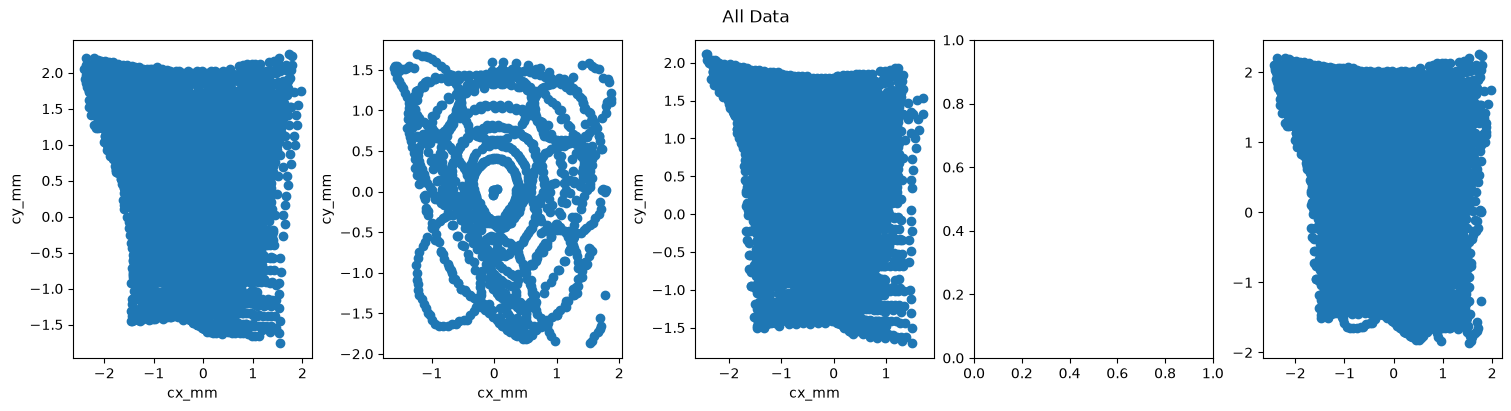

In [3]:
data_0 = pd.read_csv("processed_data/16Oct_data_corrected.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_1 = pd.read_csv("processed_data/27Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_2 = pd.read_csv("processed_data/28Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_3 = pd.read_csv("processed_data/29Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_0 = data_0.dropna()
data_1 = data_1.dropna()
data_2 = data_2.dropna()
data_3 = data_3.dropna()
data_list = [ data_1, data_2, data_3] #data_0, #get better results without data_0

all_data = pd.concat(data_list, ignore_index=True)

fig, axs = plt.subplots(1, 5, figsize=(15,4), constrained_layout=True)
for i, data in enumerate(data_list):
    subplot = axs[i]
    subplot.scatter(data["cx_mm"], data["cy_mm"])
    subplot.set_xlabel("cx_mm")
    subplot.set_ylabel("cy_mm")
axs[4].scatter(all_data["cx_mm"], all_data["cy_mm"])
fig.suptitle("All Data")

<h2> Create StandardScalers based on all data

In [4]:
scalerX = StandardScaler().fit(all_data[["cx_mm", "cy_mm"]])
scalerY = StandardScaler().fit(all_data[["s0", "s1", "s2"]])

<h2>Scale all datasets</h2>
This was for when I was going to train the model on each dataset sequentially. 

Now I am just training it on all of them concatenated, so it is not needed

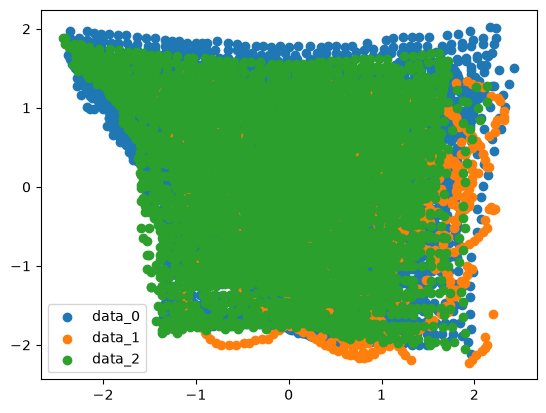

In [5]:
scaled = {}
for i, data in enumerate(data_list):
    scaled[f"X_scaled_{i}"] = scalerX.transform(data[["cx_mm", "cy_mm"]])
    scaled[f"y_scaled_{i}"] = scalerY.transform(data[["s0", "s1", "s2"]])
    plt.scatter(scaled[f"X_scaled_{i}"][:,0], scaled[f"X_scaled_{i}"][:,1], label=f"data_{i}")
    plt.legend()
#plotting just to check that they have all scaled correctly. 

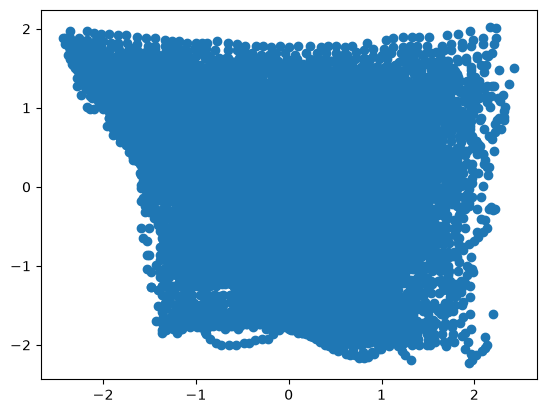

In [6]:
X_scaled_all = scalerX.transform(all_data[["cx_mm", "cy_mm"]])
y_scaled_all = scalerY.transform(all_data[["s0", "s1", "s2"]])
plt.scatter(X_scaled_all[:,0], X_scaled_all[:,1])
#plotting just to check that they have all scaled correctly. 

<h1>Linear Regression

In [7]:
def plot_motors(y_test, y_pred, lims, scaled): 
    fig, axs = plt.subplots(1, 3, constrained_layout=True)

    for i,motor in enumerate(["s0", "s1", "s2"]):
        subplot = axs[i]
        subplot.scatter(y_test[:,i], y_pred[:,i])
        subplot.set_xlabel('True Values')
        subplot.set_ylabel('Predictions')
        _ =subplot.plot(lims, lims, color="red")
        subplot.set_title(motor)
        subplot.plot()
    fig.suptitle(f"Motor Values, {scaled}")

Fold, 0:
  Train: index=0 to 1820 
  Test:  index=1821 to 3639

Linear Regression Results:
  Overall R2:  0.9061
  Weighted R2: 0.9037
Fold, 1:
  Train: index=0 to 3639 
  Test:  index=3640 to 5458

Linear Regression Results:
  Overall R2:  0.8863
  Weighted R2: 0.8861
Fold, 2:
  Train: index=0 to 5458 
  Test:  index=5459 to 7277

Linear Regression Results:
  Overall R2:  0.9365
  Weighted R2: 0.9281
Fold, 3:
  Train: index=0 to 7277 
  Test:  index=7278 to 9096

Linear Regression Results:
  Overall R2:  0.9120
  Weighted R2: 0.9084
MSE scores for each fold: [0.07956517487764359, 0.10555937886238098, 0.052331387996673584, 0.07848306745290756]


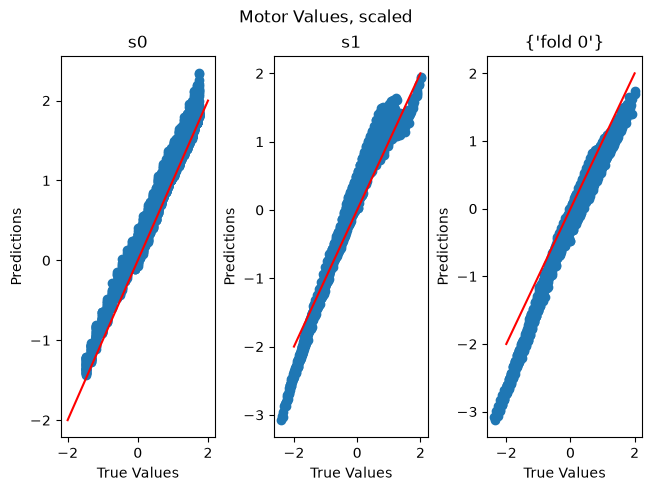

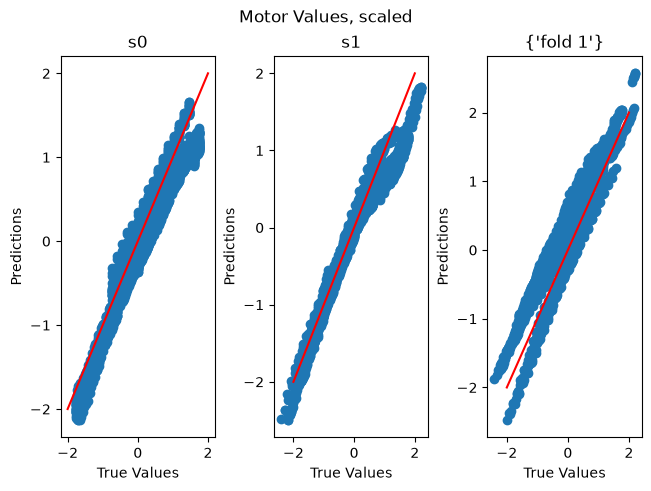

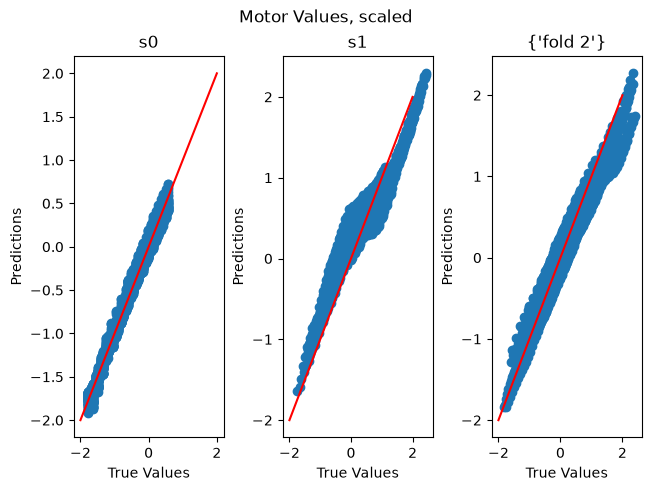

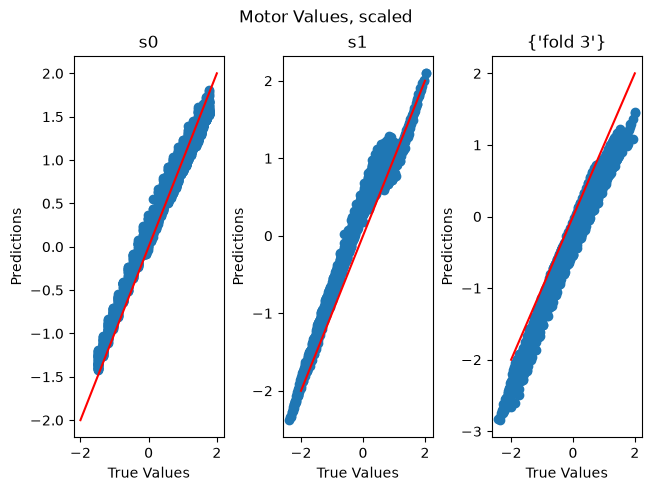

In [16]:
#LR sklearn - all data concat trained. 
scores = []

X = X_scaled_all
y = y_scaled_all

tscv = TimeSeriesSplit(n_splits=4) #, test_size=712
for i, (train_index, test_index) in enumerate(tscv.split(X)):
    print(f"Fold, {i}:")
    print(f"  Train: index={train_index[0]} to {train_index[-1]} ")
    print(f"  Test:  index={test_index[0]} to {test_index[-1]}")
    
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    lin_reg = LinearRegression()
    lin_reg.fit(X_train, y_train)
    y_pred = lin_reg.predict(X_test)
    evaluate_model("Linear Regression", y_test, y_pred)

    plot_motors(y_test, y_pred, [-2,2], scaled="scaled")

    error = mean_squared_error(y_test, y_pred)
    scores.append(error)
    plt.title({f"fold {i}"})

print("MSE scores for each fold:", scores)

In [9]:
mesh0045_27Oct = pd.read_csv("processed_data/27Oct_0045_mesh.csv")
# plt.scatter(mesh0045_27Oct["x"], mesh0045_27Oct["y"], c=mesh0045_27Oct["point"])
# plt.colorbar()
# plt.title("x and y values input into snake scan. (color=index)")
snake_predictions = lin_reg.predict(mesh0045_27Oct[["x", "y"]])
snake_pred_inverse = scalerY.inverse_transform(snake_predictions)
print(snake_pred_inverse)
np.savetxt("predictions/all_data_LR_Pred_snake_mesh.csv", snake_pred_inverse, delimiter=',')

[[ 4516.15149767 -5841.08534267  1324.93579513]
 [ 4487.44794485 -5530.40448548  1042.95853623]
 [ 4458.74439203 -5219.72362829   760.98127733]
 ...
 [-4380.21590273  5629.60942475 -1249.39051184]
 [-4408.91945555  5940.29028194 -1531.36777074]
 [-4437.62300837  6250.97113913 -1813.34502965]]


/scratch/dvu71330/grad_project_3/DeltabotProject/TensorFlow/.venv/lib64/python3.12/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


Surprisingly high R2 for Linear Regression - maybe a mistake ?

Try with tensorflow too

<h2> LR with tensorflow</h2>
A single layer MLP with a linear activation function should give a linear regression model.

W0000 00:00:1795516353.792590 3760256 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Fold, 0:
  Train: index=0 to 1820 
  Test:  index=1821 to 3639
1

Fold: 0 Results (scaled):
  Overall R2:  -0.5982
  Weighted R2: -0.4683
Fold, 1:
  Train: index=0 to 3639 
  Test:  index=3640 to 5458
1

Fold: 1 Results (scaled):
  Overall R2:  0.3909
  Weighted R2: 0.3887
Fold, 2:
  Train: index=0 to 5458 
  Test:  index=5459 to 7277
1

Fold: 2 Results (scaled):
  Overall R2:  0.3794
  Weighted R2: 0.2735
Fold, 3:
  Train: index=0 to 7277 
  Test:  index=7278 to 9096
1

Fold: 3 Results (scaled):
  Overall R2:  0.4452
  Weighted R2: 0.4222
MSE scores for each fold: [1.2133923768997192, 0.5667879581451416, 0.5288380980491638, 0.495320200920105]


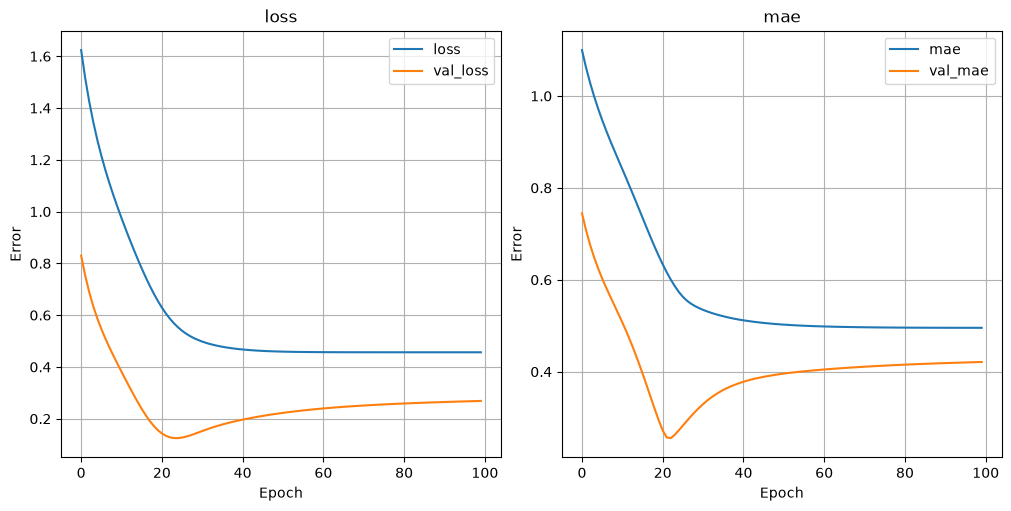

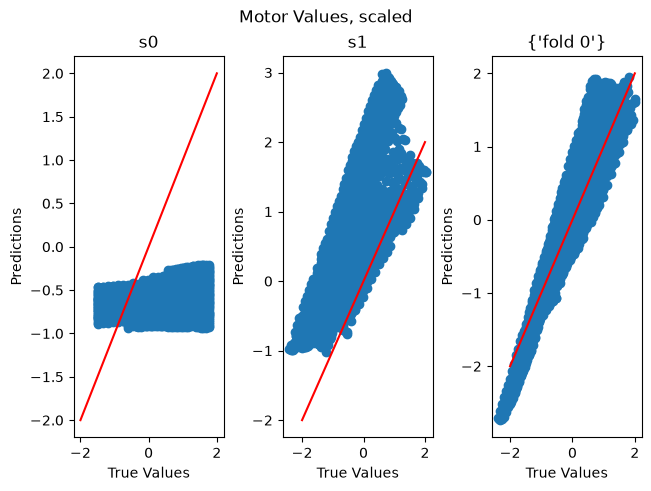

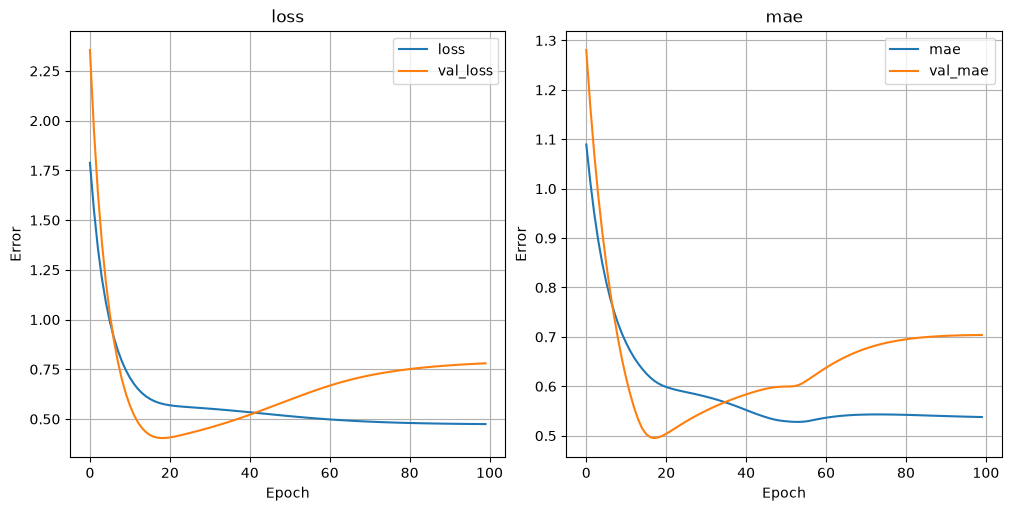

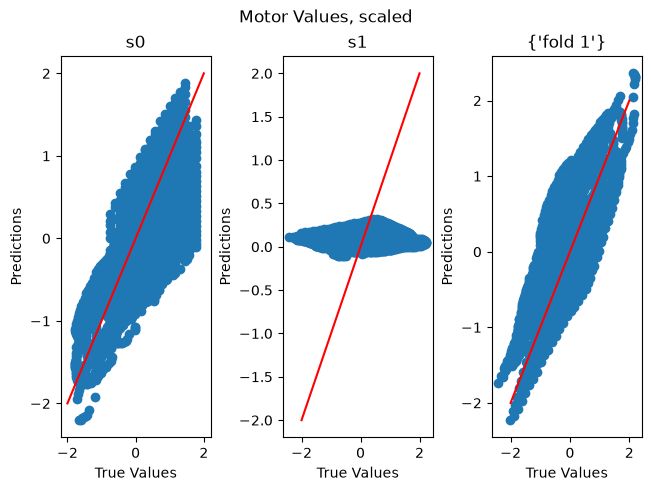

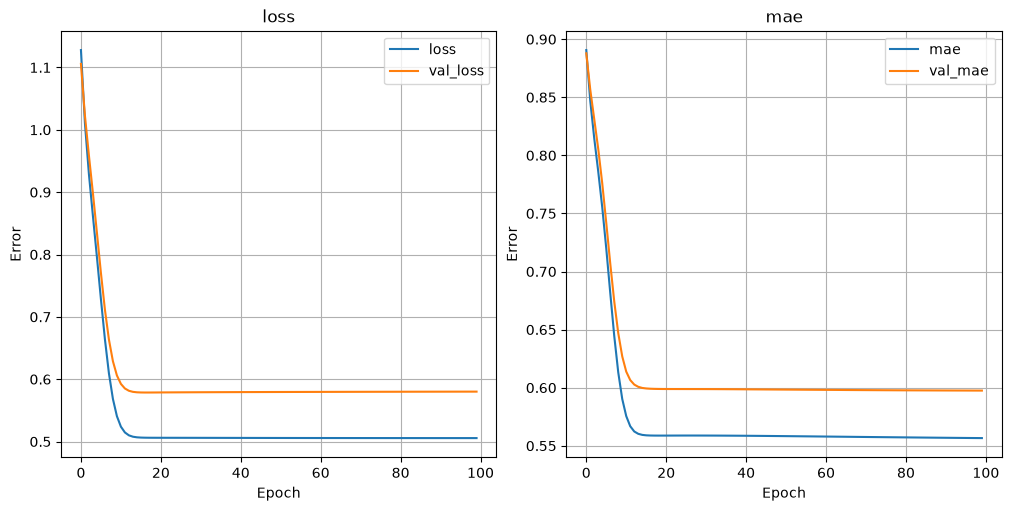

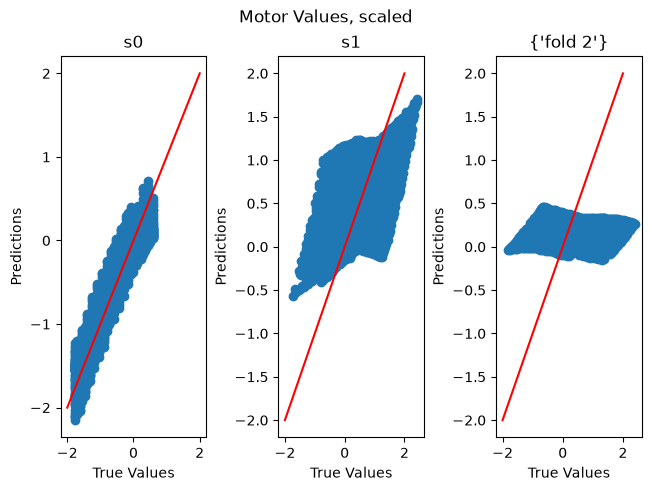

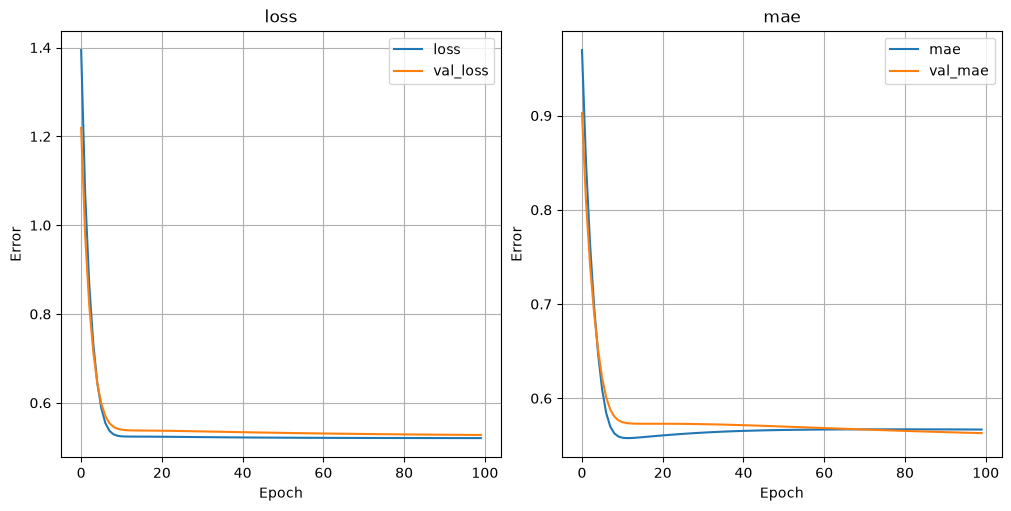

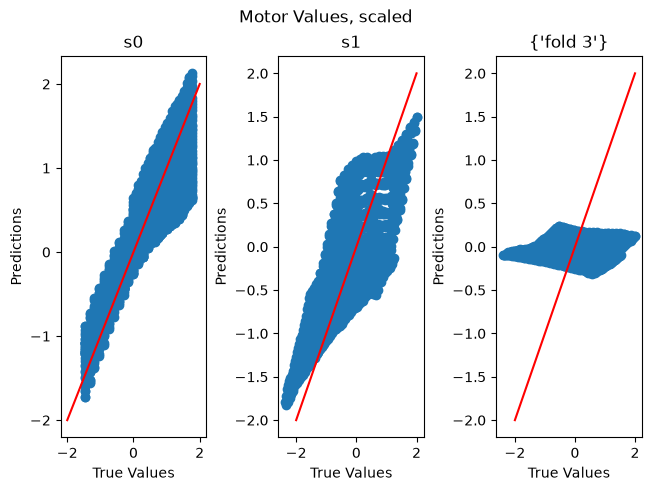

In [10]:
#LR tensorflow - all data concat trained. 
scores = []

X = X_scaled_all
y = y_scaled_all

tscv = TimeSeriesSplit(n_splits=4) #, test_size=712
for i, (train_index, test_index) in enumerate(tscv.split(X)):
    print(f"Fold, {i}:")
    print(f"  Train: index={train_index[0]} to {train_index[-1]} ")
    print(f"  Test:  index={test_index[0]} to {test_index[-1]}")
    
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    model =  tf.keras.models.Sequential(
    [
        tf.keras.layers.Input(shape=(X_train.shape[1],)),
        tf.keras.layers.Dense(
            units=1, activation="linear"
        ),  # Linear activation = Linear Regression
        tf.keras.layers.Dense(y_train.shape[1],)
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='mse',
        metrics=['mae'])
    

    history = train_model(model, X_train, y_train, verbose=0, epochs=100, patience=1)
    y_pred = model.predict(X_test, verbose=0)

    evaluate_model(f"Fold: {i}", y_test, y_pred, is_scaled=True)

    plot_loss_and_mae(history)

    plot_motors(y_test, y_pred, [-2,2], scaled="scaled")

    error = mean_squared_error(y_test, y_pred)
    scores.append(error)
    plt.title({f"fold {i}"})

print("MSE scores for each fold:", scores)

<h1>MLP

setup

In [11]:
def plot_converted_loss(loss, val_loss):
  fig, axs = plt.subplots(1, 2, figsize=(10,5), constrained_layout=True)
  for i, value in enumerate(['loss']):
    subplot = axs[i]
    subplot.plot(loss, label=value)
    subplot.plot(val_loss, label=f'val_{value}')
  #   plt.ylim([0, 10])
    subplot.set_xlabel('Epoch')
    subplot.set_ylabel('Error')
    subplot.legend()
    subplot.grid(True)
    subplot.set_title(value)
  fig.suptitle("Converted MSE to Motor Counts (squared)")

In [12]:
all_data["motor_squared"] = all_data["s1"] * all_data["s1"]
display(all_data["motor_squared"].head(5))
scalerError = StandardScaler().fit(all_data[["motor_squared"]])

0           0.0
1           0.0
2    70442448.0
3    63186600.0
4    56340036.0
Name: motor_squared, dtype: float32

In [13]:
def build_nn_model(input_dim, output_dim, architecture='standard'):
    """Build a neural network model with specified architecture"""
    
    if architecture == 'standard':
        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(input_dim,)),
            tf.keras.layers.Dense(64, activation='relu'),
            tf.keras.layers.Dense(32, activation='relu'),
            tf.keras.layers.Dense(output_dim)
        ])

    model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae'])

    return model

<h2>MLP training on each dataset separately - old 

In [14]:
# training pm data adding each data set separately 
# model = build_nn_model(2, 3) #usually not hardcoded - X_train_scaled.shape[1], y_train_scaled.shape[1]
# model.summary() #investigate
# scores = []

# tscv = TimeSeriesSplit(n_splits=3) #, test_size=712
# for data in range(3):
#     X = scaled[f"X_scaled_{data}"]
#     y = scaled[f"y_scaled_{data}"]
#     for i, (train_index, test_index) in enumerate(tscv.split(X)):
#         print(f"Fold{data}, {i}:")
#         print(f"  Train: index={train_index[0]} to {train_index[-1]} ")
#         print(f"  Test:  index={test_index[0]} to {test_index[-1]}")
        
#         X_train, X_test = X[train_index], X[test_index]
#         y_train, y_test = y[train_index], y[test_index]

#         model = build_nn_model(X_train.shape[1], y_train.shape[1])

#         history = train_model(model, X_train, y_train, verbose=0, epochs=50, patience=1)
#         y_pred = model.predict(X_test, verbose=0)

#         evaluate_model(f"Fold: {i}", y_test, y_pred, is_scaled=True)
#         # plot_motors(y_test, y_pred, [-2,2])

#         error = mean_squared_error(y_test, y_pred)
#         scores.append(error)
#         # plot_loss_and_mae(history)
#         loss = history.history['loss']
#         val_loss = history.history['val_loss']
#         converted_loss = scalerError.inverse_transform(np.sqrt(loss).reshape(-1, 1))
#         converted_val_loss = scalerError.inverse_transform(np.sqrt(val_loss).reshape(-1, 1))
#         plot_converted_loss(converted_loss, converted_val_loss)
#         # break

# print("MSE scores for each fold:", scores)

<h2>MLP training with all data concatenated

Fold, 0:
  Train: index=0 to 1820 
  Test:  index=1821 to 3639
Fold, 1:
  Train: index=0 to 3639 
  Test:  index=3640 to 5458
Fold, 2:
  Train: index=0 to 5458 
  Test:  index=5459 to 7277
Fold, 3:
  Train: index=0 to 7277 
  Test:  index=7278 to 9096
30

Fold: 3 Results (scaled):
  Overall R2:  0.8650
  Weighted R2: 0.8602
MSE scores for each fold: [0.1198570728302002]


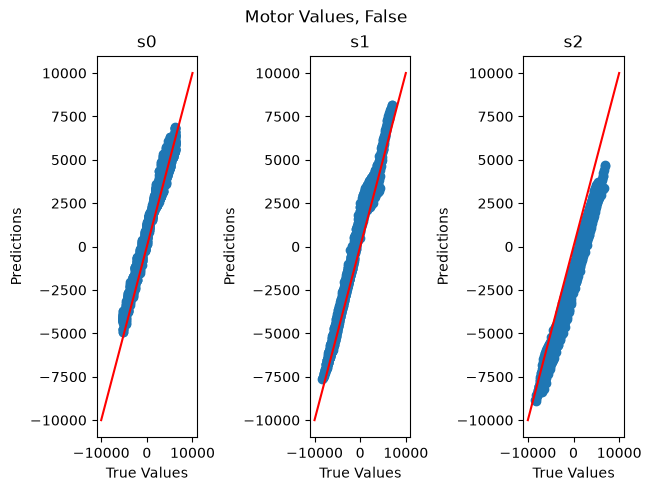

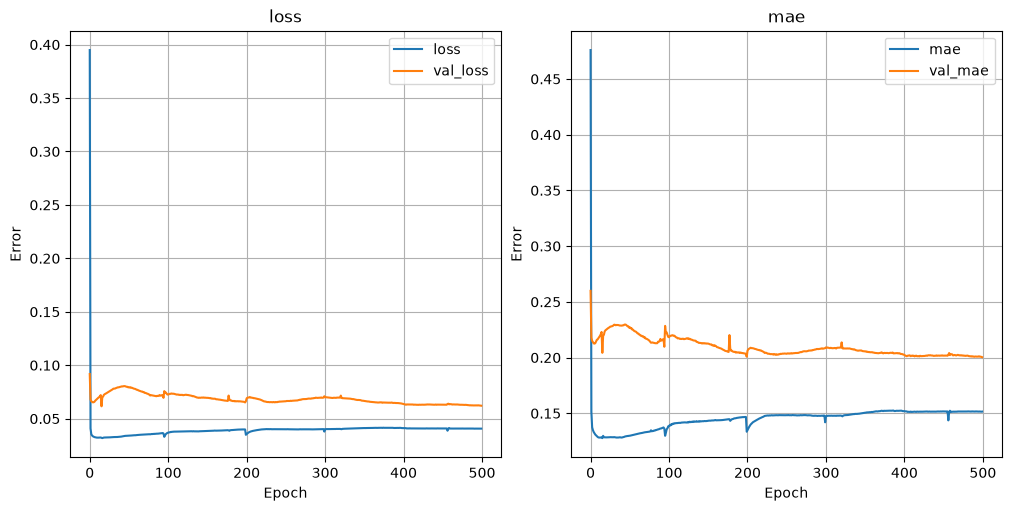

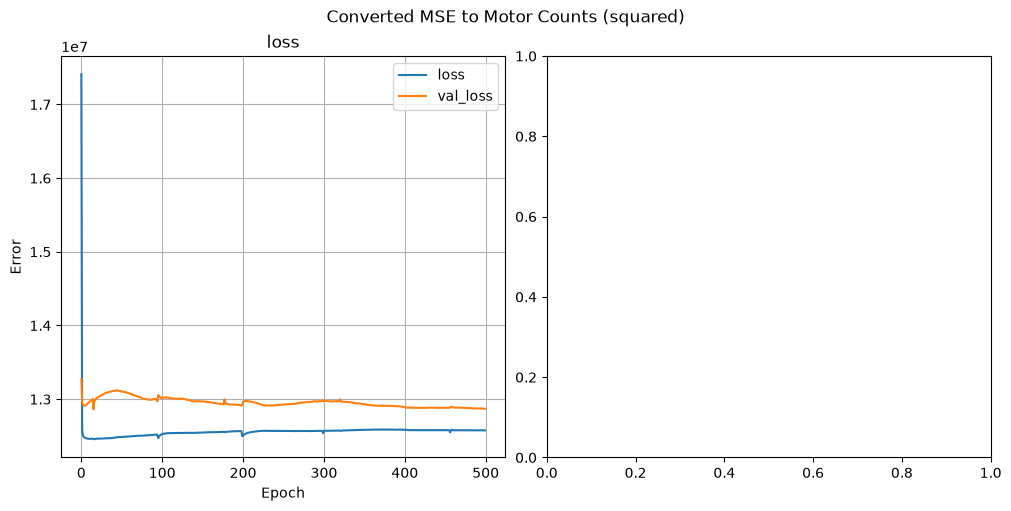

In [18]:
#Training with all data concatenated
# model = build_nn_model(2, 3) #usually not hardcoded - X_train_scaled.shape[1], y_train_scaled.shape[1]
# model.summary() #investigate
scores = []

X = X_scaled_all
y = y_scaled_all

tscv = TimeSeriesSplit(n_splits=4) #, test_size=712
for i, (train_index, test_index) in enumerate(tscv.split(X)):
    print(f"Fold, {i}:")
    print(f"  Train: index={train_index[0]} to {train_index[-1]} ")
    print(f"  Test:  index={test_index[0]} to {test_index[-1]}")
    
X_train, X_test = X[train_index], X[test_index]
y_train, y_test = y[train_index], y[test_index]

model = build_nn_model(X_train.shape[1], y_train.shape[1])

history = train_model(model, X_train, y_train, verbose=0, epochs=500)
y_pred = model.predict(X_test, verbose=0)

evaluate_model(f"Fold: {i}", y_test, y_pred, is_scaled=True)

y_test_inverse = scalerY.inverse_transform(y_test)
y_pred_inverse = scalerY.inverse_transform(y_pred)
plot_motors(y_test_inverse, y_pred_inverse, [-10000,10000], False)

error = mean_squared_error(y_test, y_pred)
scores.append(error)
plot_loss_and_mae(history)
# plt.title({f"Data, fold {i}"})
loss = history.history['loss']
val_loss = history.history['val_loss']
converted_loss = scalerError.inverse_transform(np.array(loss).reshape(-1,1))
converted_val_loss = scalerError.inverse_transform(np.array(val_loss).reshape(-1,1))
plot_converted_loss(converted_loss, converted_val_loss)

print("MSE scores for each fold:", scores)

<h1> Using final model to predict basic snake scan 

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 862us/step
[[ 4958.102    -4866.447       35.780846]
 [ 4953.664    -4646.0103    -191.7842  ]
 [ 4948.992    -4439.1567    -388.8665  ]
 ...
 [-4496.563     6921.5693   -2358.2422  ]
 [-4459.671     7127.6724   -2601.7249  ]
 [-4451.6577    7320.8745   -2795.8777  ]]


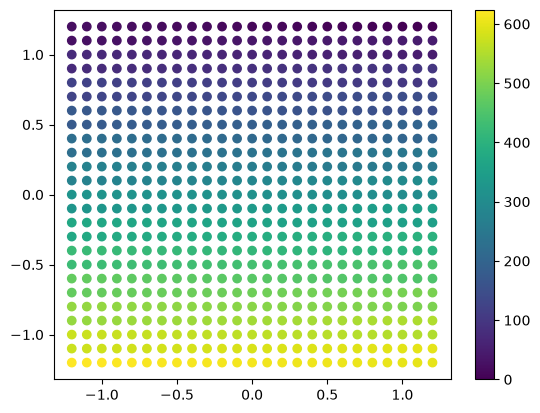

In [ ]:
mesh0045_27Oct = pd.read_csv("processed_data/27Oct_0045_mesh.csv") #get basic snake scan x and y values
plt.scatter(mesh0045_27Oct["x"], mesh0045_27Oct["y"], c=mesh0045_27Oct["point"])
plt.colorbar()
snake_predictions = model.predict(mesh0045_27Oct[["x", "y"]])
snake_pred_inverse = scalerY.inverse_transform(snake_predictions)
print(snake_pred_inverse)
np.savetxt("predictions/all_data_MLP_pred_snake.csv", snake_pred_inverse, delimiter=',')